# CPE393 Text Analytics — Lab: Investigating Neural Text Classification

**Dataset:** IMDb movie reviews  
**Core idea:** Representation → Model → Evaluation → Error Analysis

This is a guided investigation, not a run-all notebook. Several cells deliberately contain `TODO`s or ask you to predict an output **before** you run the next cell.

## Learning objectives
1. Compare Bag-of-Words (word counts) and TF–IDF.
2. Distinguish token IDs from learned embeddings.
3. Explain what is lost when embeddings are averaged.
4. Motivate CNNs and sequence models from observed limitations.
5. Compare models consistently.
6. Diagnose errors and form evidence-based hypotheses.

> **Rule for today:** Do not judge a model only by final accuracy. Inspect what goes into it and where it fails.

## 0. Setup

Run this once. Later cells are intentionally small so you can inspect intermediate representations.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

I0000 00:00:1790825041.833422  411034 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790825041.839350  411034 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1790825042.409313  411034 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790825051.533075  411034 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

TensorFlow: 2.21.0


# 1. Start with the text, not the model

Keras's IMDb dataset is stored as **integer word IDs**. We want readable text because we will construct several representations ourselves.

In [2]:
VOCAB_SIZE = 10_000
TRAIN_SIZE = 10_000
TEST_SIZE = 5_000

(x_train_ids, y_train_full), (x_test_ids, y_test_full) = keras.datasets.imdb.load_data(
    num_words=VOCAB_SIZE
)

print("First encoded review — first 30 IDs:")
print(x_train_ids[0][:30])
print("\nLabel:", y_train_full[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
First encoded review — first 30 IDs:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480]

Label: 1


In [10]:
len(x_train_ids[0]),len(x_train_ids[1])

(218, 189)

### Stop and think 1

**Q1.1** Are these numbers already word embeddings? Why or why not?
I assume that on each id is each review of lenght $n$, and the number is the index of word in the corpus(distinct word)

**Q1.2** What information would you need to convert IDs such as `14` and `22` back into readable words?
to know the whole corpus, in order, and we can resolve it

## 1.1 Build an ID → word lookup

`get_word_index()` gives a word-to-index dictionary. Inspect it first.

In [12]:
word_index = keras.datasets.imdb.get_word_index()

print("Some entries:")
print(list(word_index.items())[:10])

Some entries:
[('fawn', 34701), ('tsukino', 52006), ('nunnery', 52007), ('sonja', 16816), ('vani', 63951), ('woods', 1408), ('spiders', 16115), ('hanging', 2345), ('woody', 2289), ('trawling', 52008)]


### Prediction checkpoint

Keras reserves:
- `0` → padding
- `1` → start of review
- `2` → unknown / out-of-vocabulary
- `3` → unused

Normal word indices are therefore shifted by 3.

**Q1.3** Why is the `+3` needed below?
as said, since word index is the extended of the `word_index` that we insert the 3 case for that. so it is match the kerase standard when we do the reverse word index

In [13]:
reverse_word_index = {index + 3: word for word, index in word_index.items()}

reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

for i in range(12):
    print(i, "→", reverse_word_index.get(i, "<UNK>"))

0 → <PAD>
1 → <START>
2 → <UNK>
3 → <UNUSED>
4 → the
5 → and
6 → a
7 → of
8 → to
9 → is
10 → br
11 → in


## 1.2 What should we remove when decoding?

A decoder using `if i > 3` also removes `<UNK>`.

For this lab, **keep `<UNK>` visible** so you can see where vocabulary information has been lost.

**Q1.4** Which special IDs should be removed if we want to remove padding, start, and unused tokens—but keep unknown words?
0,1,3
Complete the set below.

In [14]:
def decode_review(ids):
    # TODO: IDs for <PAD>, <START>, and <UNUSED>.
    # Keep <UNK> visible.
    remove_ids = {0,1,3}

    return " ".join(
        reverse_word_index.get(i, "<UNK>")
        for i in ids
        if i not in remove_ids
    )

Test your decoder. Look specifically for `<UNK>`.

In [15]:
decoded_example = decode_review(x_train_ids[0])

print(decoded_example[:1200])
print("\nContains <UNK>:", "<UNK>" in decoded_example)

this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they h

### Q1.5 — Unknown words

If `<UNK>` appears, what does it tell you about the relationship among:
- the original review,
- `VOCAB_SIZE = 10,000`, and
- the representation available to the classifier?

Would increasing vocabulary size necessarily be better in every situation?

more vocab size = less unknown for sure

## 1.3 Decode the working subset

In [16]:
train_texts = np.array(
    [decode_review(x) for x in x_train_ids[:TRAIN_SIZE]], dtype=object
)
train_labels = np.array(y_train_full[:TRAIN_SIZE])

test_texts = np.array(
    [decode_review(x) for x in x_test_ids[:TEST_SIZE]], dtype=object
)
test_labels = np.array(y_test_full[:TEST_SIZE])

print("Train:", train_texts.shape, train_labels.shape)
print("Test :", test_texts.shape, test_labels.shape)

Train: (10000,) (10000,)
Test : (5000,) (5000,)


## 1.4 Inspect the corpus

Complete the missing expression so `words` stores the number of whitespace-separated tokens in each review.

In [20]:
train_df = pd.DataFrame({"text": train_texts, "label": train_labels})

print(train_df.iloc[:10,:]["text"])
print(words:=train_df["text"].str.split().apply(len))
# TODO
train_df["words"] = words

display(train_df.head(3))

0    this film was just brilliant casting location ...
1    big hair big boobs bad music and a giant safet...
2    this has to be one of the worst films of the 1...
3    the <UNK> <UNK> at storytelling the traditiona...
4    worst mistake of my life br br i picked this m...
5    begins better than it ends funny that the russ...
6    lavish production values and solid performance...
7    the <UNK> tells the story of the four hamilton...
8    just got out and cannot believe what a brillia...
9    this movie has many problem associated with it...
Name: text, dtype: str
0       217
1       188
2       140
3       549
4       146
       ... 
9995    154
9996    532
9997    140
9998    126
9999    148
Name: text, Length: 10000, dtype: int64


,text,label,words
0,this film was just brilliant casting location ...,1,217
1,big hair big boobs bad music and a giant safet...,0,188
2,this has to be one of the worst films of the 1...,0,140


Class counts:
label
0    4947
1    5053
Name: count, dtype: int64


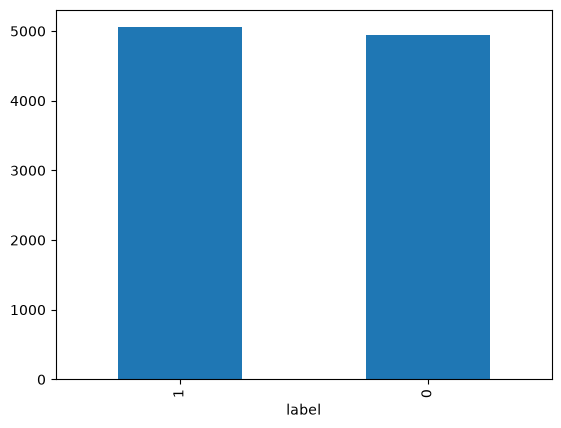


Review length:


count    10000.00000
mean       237.86000
std        176.34177
min         10.00000
25%        129.00000
50%        177.00000
75%        291.00000
max       1850.00000
Name: words, dtype: float64

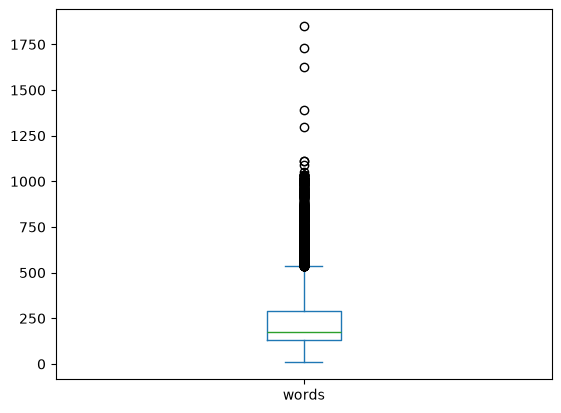

<Axes: ylabel='Frequency'>

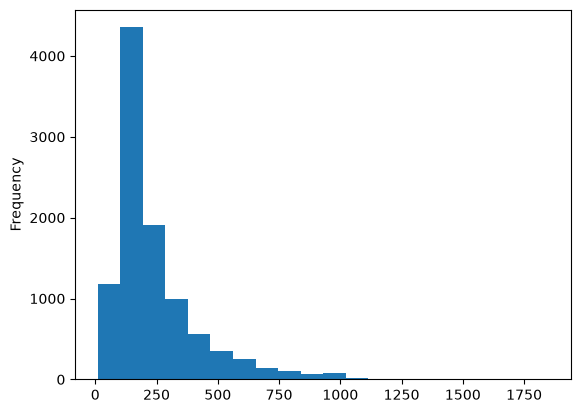

In [31]:
print("Class counts:")
print(train_df["label"].value_counts().sort_index())
train_df.label.value_counts().plot.bar()
plt.show()

print("\nReview length:")
display(train_df["words"].describe())
train_df['words'].plot.box()
plt.show()
train_df.words.plot.hist(bins=20)

### Q1.6

1. Is the subset approximately balanced?
it is quite balance, with each label around 5k rows
2. Do reviews have similar lengths?
not quite, from the distribution , there are a lot of outliers too. even though most of it is within between 0 - 500 of length, mean is less than 250. so that's quite. also from the distribution that it is right skewed.
3. Name one linguistic characteristic you expect to make sentiment classification difficult.
variability, maybe same phrase could mean totally different. due to case like sarcasm

---
# 2. Representation 1 — Bag of Words (word counts)

Here Bag of Words means a vector of **word occurrence counts** produced by `CountVectorizer`.

### Predict first

Suppose the vocabulary order is:

`["bad", "good", "movie", "very"]`

What vector represents:

`"very good movie good"`?

Write it down before continuing.
`[3,1,2,1]`

## 2.1 Fit CountVectorizer

Complete the methods. Training should learn the vocabulary; test data should use that same vocabulary.

In [33]:
count_vectorizer = CountVectorizer(
    max_features=VOCAB_SIZE,
    stop_words=None
)

X_train_count = count_vectorizer.fit_transform(train_texts)
X_test_count = count_vectorizer.transform(test_texts)

print("Train matrix:", X_train_count.shape)
print("Test matrix :", X_test_count.shape)

Train matrix: (10000, 9770)
Test matrix : (5000, 9770)


## 2.2 Inspect one count vector before training any classifier

In [34]:
review_id = 0

count_features = count_vectorizer.get_feature_names_out()
count_row = X_train_count[review_id]
nonzero = count_row.nonzero()[1]

word_counts = [
    (count_features[i], int(count_row[0, i]))
    for i in nonzero
]

print(train_texts[review_id][:500])
print("\nFirst 25 non-zero count features:")
print(word_counts[:25])

this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend 

First 25 non-zero count features:
[('this', 3), ('film', 6), ('was', 11), ('just', 4), ('brilliant', 3), ('casting', 1), ('location', 1), ('scenery', 1), ('story', 2), ('direction', 1), ('everyone', 2), ('really', 2), ('suited', 1), ('the', 15), ('part', 1), ('they', 4), ('played', 2), ('and', 9), ('you', 4), ('could', 1), ('imagine', 1), ('being', 2), ('there', 2), ('robert', 1), ('unk', 6)]


### Q2.1

- What does each dimension represent?
so in `(10000,9770)` means that we have `10000` data points and each datapoints is a vector of length `9770`(same as amount of vocab)
- Why is the matrix sparse?
because in each review, we will only have limited vocab in it, limited contribution to the central corpus. so only a fraction is on the count but others will be $0$
- What information about word order is missing?
the order, since we give it up when using bag of word to count vectorizer

## 2.3 Train Naive Bayes on word counts

Complete the training and prediction lines.

In [38]:
nb_count = MultinomialNB()

# TODO: train
nb_count.fit(X_train_count,train_labels)

# TODO: predict
count_pred = nb_count.predict(X_test_count)

print(classification_report(
    test_labels, count_pred,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.81      0.86      0.84      2571
    Positive       0.85      0.79      0.82      2429

    accuracy                           0.83      5000
   macro avg       0.83      0.83      0.83      5000
weighted avg       0.83      0.83      0.83      5000



---
# 3. Representation 2 — TF–IDF

Keep the same raw reviews and classifier family, but change the representation.

`Counts + Naive Bayes` vs. `TF–IDF + Naive Bayes`

## 3.1 Build TF–IDF features

Complete the two transformations.

In [39]:
tfidf = TfidfVectorizer(
    max_features=VOCAB_SIZE,
    stop_words=None
)

X_train_tfidf = tfidf.fit_transform(train_texts)
X_test_tfidf = tfidf.transform(test_texts)

print(X_train_tfidf.shape)

(10000, 9770)


## 3.2 Inspect TF–IDF for the SAME review

In [40]:
tfidf_features = tfidf.get_feature_names_out()
tfidf_row = X_train_tfidf[review_id]
nonzero = tfidf_row.nonzero()[1]

word_tfidf = [
    (tfidf_features[i], round(float(tfidf_row[0, i]), 3))
    for i in nonzero
]

print("COUNT FEATURES:")
print(word_counts[:20])

print("\nTF-IDF FEATURES:")
print(word_tfidf[:20])

COUNT FEATURES:
[('this', 3), ('film', 6), ('was', 11), ('just', 4), ('brilliant', 3), ('casting', 1), ('location', 1), ('scenery', 1), ('story', 2), ('direction', 1), ('everyone', 2), ('really', 2), ('suited', 1), ('the', 15), ('part', 1), ('they', 4), ('played', 2), ('and', 9), ('you', 4), ('could', 1)]

TF-IDF FEATURES:
[('this', 0.059), ('film', 0.169), ('was', 0.282), ('just', 0.134), ('brilliant', 0.222), ('casting', 0.086), ('location', 0.095), ('scenery', 0.091), ('story', 0.078), ('direction', 0.071), ('everyone', 0.127), ('really', 0.077), ('suited', 0.113), ('the', 0.27), ('part', 0.054), ('they', 0.132), ('played', 0.124), ('and', 0.166), ('you', 0.114), ('could', 0.044)]


### Q3.1 — Compare, don't just define

1. What changed from Count to TF–IDF?
it is no more the multi-hot encoding from the existence of each token
2. What stayed the same?
the absent of order information
3. Does TF–IDF solve the word-order limitation of Bag of Words?
it doesn't go on totally naive on only existence of it, we also encode the importance and uniqueness of the term in each document, but the missing of order is there

## 3.3 Train the same classifier on TF–IDF

In [42]:
nb_tfidf = MultinomialNB()

# TODO: fit and predict
nb_tfidf.fit(X_train_tfidf,train_labels)
tfidf_pred = nb_tfidf.predict(X_test_tfidf)

print(classification_report(
    test_labels, tfidf_pred,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.84      0.87      0.85      2571
    Positive       0.86      0.82      0.84      2429

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.85      5000
weighted avg       0.85      0.85      0.85      5000



---
# 4. First comparison: representation matters

Complete the missing accuracy calculation.

In [43]:
def metric_row(name, y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0
    )
    return {
        "Model": name,
        "Accuracy": (y_true == y_pred).sum() / y_true.size,
        "Precision": p,
        "Recall": r,
        "F1": f1
    }

In [44]:
traditional_results = pd.DataFrame([
    metric_row("Count + Naive Bayes", test_labels, count_pred),
    metric_row("TF-IDF + Naive Bayes", test_labels, tfidf_pred)
])

display(traditional_results.round(4))

,Model,Accuracy,Precision,Recall,F1
0,Count + Naive Bayes,0.8268,0.8453,0.7876,0.8154
1,TF-IDF + Naive Bayes,0.8468,0.8576,0.8209,0.8389


### Q4.1 — Interpret

1. Which representation performed better **in this run**?
`tf_idf` is better by `0.02` percent accuracy and f1
2. Would you immediately declare it universally better?
it is not **significantly** better
3. What useful information do **both** still discard?
order

---
# 5. Neural representation — token IDs are not embeddings

Pipeline:

`raw text → token IDs → embeddings → document representation → classifier`

In [46]:
MAX_TOKENS = 10_000
SEQUENCE_LENGTH = 300
EMBED_DIM = 64
BATCH_SIZE = 64

## 5.1 Build the neural text vectorizer

Complete `output_mode` so the result is integer token IDs.

In [47]:
vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation"
)

vectorizer.adapt(train_texts)

E0000 00:00:1790827493.353054  411034 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### Predict before running

For **one** review:
- What shape should the vectorized output have? 300, truncated or padded by 0, define by `SEQUENCE_LENGTH`
- Are these 300 values embeddings? yes

In [49]:
sample = train_texts[0]
sample_ids = vectorizer(tf.constant([sample]))

print("Original text:")
print(sample[:300])
print("\nVectorized shape:", sample_ids.shape)
print("First 30 token IDs:")
print(sample_ids.numpy()[0][:30])

Original text:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact th

Vectorized shape: (1, 300)
First 30 token IDs:
[  13   21   15   44  505 1016 1550 1283   65  481 5013   62 3831    3
  168   36  257    5   24  101   44  816  107   48  628    2    8   35
  476  274]


## 5.2 Inspect token ↔ ID mapping

In [50]:
neural_vocab = vectorizer.get_vocabulary()

for token_id in sample_ids.numpy()[0][:20]:
    if token_id < len(neural_vocab):
        print(int(token_id), "→", neural_vocab[int(token_id)])

13 → this
21 → film
15 → was
44 → just
505 → brilliant
1016 → casting
1550 → location
1283 → scenery
65 → story
481 → direction
5013 → everyones
62 → really
3831 → suited
3 → the
168 → part
36 → they
257 → played
5 → and
24 → you
101 → could


### Q5.1

What does an integer token ID represent? Why does a larger ID **not** mean a more important or more positive word?
it is just a index

## 5.3 Inspect an Embedding layer BEFORE classifier training

Create it separately so the intermediate output is visible.

In [51]:
embedding_layer = layers.Embedding(
    input_dim=MAX_TOKENS,
    output_dim=EMBED_DIM,
    mask_zero=True
)

sample_embeddings = embedding_layer(sample_ids)

print("Token IDs shape :", sample_ids.shape)
print("Embedding shape :", sample_embeddings.shape)

Token IDs shape : (1, 300)
Embedding shape : (1, 300, 64)


### Q5.2 — Shape reasoning

Explain the three dimensions of the embedding output.

as 1 is one review, 300 as the size of each review - padded, and then each token will be represented by vector of 64

### Q5.3 — Word2Vec connection

Are these Word2Vec vectors? yes

Where did their initial values come from, and what training objective will eventually update them? initialize randomly and then learned after the NN

In [52]:
print("Token:", neural_vocab[int(sample_ids[0, 0])])
print(sample_embeddings[0, 0, :10].numpy())

print("\nToken:", neural_vocab[int(sample_ids[0, 1])])
print(sample_embeddings[0, 1, :10].numpy())

Token: this
[-0.01587968  0.014062    0.01974915  0.01822606 -0.03160763 -0.00028857
 -0.01255069  0.03878717 -0.01109613 -0.03291299]

Token: film
[ 0.01853384  0.03404872  0.02485038  0.00931472  0.00462385  0.0383786
 -0.01462662 -0.0316146   0.00489931  0.04161069]


Before classifier training, should similarity between these randomly initialized vectors be linguistically meaningful? Why?
yes, as either the skip-gram or cbow techniques that we discussed from earlier lecture - it doesn encode the similarity by co-occurence and context so it should be LINGUISTICLY MEANINGFUL

---
# 6. Deliberately simple neural classifier: average the embeddings

Predict the missing dimensionality:

`300 token IDs → 300 × 64 embeddings → 64 values after averaging`

What information might averaging destroy?
fine grained detials that each token might contribute, it got average

In [54]:
avg_model = keras.Sequential([
    layers.Input(shape=(), dtype=tf.string),
    vectorizer,
    embedding_layer,
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="average_embedding_classifier")

avg_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

avg_model.summary()

Model: "average_embedding_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 300)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 300, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 642,113 (2.45 MB)

 Trainable params: 642,113 (2.45 MB)

 Non-trainable params: 0 (0.00 B)

### Q6.1 — Read the architecture

1. Which layer learns word representations?, embedding
2. Which layer produces one document vector? average
3. Why sigmoid?, for binary classification(we know from label), we clamp the output to be `[0,1]`
4. Which representation itself is updated by backpropagation? the word embedding layers, as we said it is randomly initialized and learned through NN to either techniques

In [55]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

avg_history = avg_model.fit(
    train_texts, train_labels,
    validation_split=0.2,
    epochs=8,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.7165 - loss: 0.6305 - val_accuracy: 0.8280 - val_loss: 0.4969
Epoch 2/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8686 - loss: 0.3715 - val_accuracy: 0.8595 - val_loss: 0.3364
Epoch 3/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9150 - loss: 0.2434 - val_accuracy: 0.8730 - val_loss: 0.3088
Epoch 4/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9420 - loss: 0.1762 - val_accuracy: 0.8740 - val_loss: 0.3062
Epoch 5/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9631 - loss: 0.1289 - val_accuracy: 0.8740 - val_loss: 0.3174
Epoch 6/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9771 - loss: 0.0937 - val_accuracy: 0.8745 - val_loss: 0.3366


## 6.1 Predict

Complete the 0.5 thresholding step.

In [59]:
avg_prob = avg_model.predict(
    test_texts, batch_size=BATCH_SIZE, verbose=0
).ravel()
print(avg_prob,avg_prob>= 0.5)

avg_pred = (avg_prob >= 0.5).astype(int)

print(classification_report(
    test_labels, avg_pred,
    target_names=["Negative", "Positive"]
))

[0.17639387 0.9965089  0.7511666  ... 0.997321   0.9330038  0.99444777] [False  True  True ...  True  True  True]
              precision    recall  f1-score   support

    Negative       0.89      0.85      0.87      2571
    Positive       0.84      0.89      0.86      2429

    accuracy                           0.87      5000
   macro avg       0.87      0.87      0.87      5000
weighted avg       0.87      0.87      0.87      5000



---
# 7. CNN — learn local patterns

Consider:
- `very good`
- `not very good`
- `dog bites man`
- `man bites dog`

### Q7.1
Why can average pooling be problematic here? What information should the next model preserve?
it remove fine grained contribution from some token, and the order removed too. so we should preserve those

## 7.1 Build the CNN

Complete the missing convolution layer.

In [61]:
CNN_FILTERS = 64
KERNEL_SIZE = 5

cnn_model = keras.Sequential([
    layers.Input(shape=(), dtype=tf.string),
    vectorizer,
    layers.Embedding(MAX_TOKENS, EMBED_DIM),

    # TODO: Conv1D with CNN_FILTERS, KERNEL_SIZE, ReLU
    layers.Conv1D(filters=CNN_FILTERS, kernel_size=KERNEL_SIZE, activation="relu"),

    layers.GlobalMaxPooling1D(),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
], name="cnn_text_classifier")

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "cnn_text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 300)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 300, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 296, 64)        │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 662,657 (2.53 MB)

 Trainable params: 662,657 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

### Q7.2

What does `KERNEL_SIZE = 5` mean conceptually for text? 5-gram window

Why might global **max** pooling make sense after convolution?, so on the channel, we could extract the most importance - biggest contributor of all within review rather than each window

In [62]:
cnn_history = cnn_model.fit(
    train_texts, train_labels,
    validation_split=0.2,
    epochs=8,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.5939 - loss: 0.6649 - val_accuracy: 0.7615 - val_loss: 0.5407
Epoch 2/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.8070 - loss: 0.4398 - val_accuracy: 0.8350 - val_loss: 0.3743
Epoch 3/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.9169 - loss: 0.2336 - val_accuracy: 0.8570 - val_loss: 0.3299
Epoch 4/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9783 - loss: 0.0939 - val_accuracy: 0.8585 - val_loss: 0.3633
Epoch 5/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 0.9955 - loss: 0.0319 - val_accuracy: 0.8640 - val_loss: 0.3792


In [64]:
cnn_prob = cnn_model.predict(
    test_texts, batch_size=BATCH_SIZE, verbose=0
).ravel()

# TODO
cnn_pred = (cnn_prob >= 0.5).astype(int)

print(classification_report(
    test_labels, cnn_pred,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.89      0.83      0.86      2571
    Positive       0.83      0.89      0.86      2429

    accuracy                           0.86      5000
   macro avg       0.86      0.86      0.86      5000
weighted avg       0.86      0.86      0.86      5000



---
# 8. Brief bridge: RNNs and attention

We will **not** build a full HAN today.

**CNN:** learns useful local patterns.

**RNN / LSTM / GRU:** processes tokens as a sequence, carrying a hidden state forward:

`word₁ → state₁ → word₂ → state₂ → word₃ → ...`

**Attention:** allows different token representations to contribute with different learned weights instead of treating every position equally:

`token representations → learned weights → weighted representation`

### Q8.1
Give one sentiment example where sequence information matters. when the meaning, total meaning of the review, could change after a while. like for example "I really hate the movies from this director, but turns out I like it more than I thought"

### Q8.2
Why might averaging every token equally be undesirable?, it is like we given equal weight for every token, some linguisticly useless token have equal say than those significant ones.

### Q8.3
What question does attention address that average pooling does not?
the unequal importance of each token

> HAN later extends this idea hierarchically: words → sentences → document, with attention at multiple levels.

---
# 9. Compare all core models

In [65]:
results = pd.DataFrame([
    metric_row("Count + Naive Bayes", test_labels, count_pred),
    metric_row("TF-IDF + Naive Bayes", test_labels, tfidf_pred),
    metric_row("Embedding + Average", test_labels, avg_pred),
    metric_row("Embedding + CNN", test_labels, cnn_pred)
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1
0,Count + Naive Bayes,0.8268,0.8453,0.7876,0.8154
1,TF-IDF + Naive Bayes,0.8468,0.8576,0.8209,0.8389
2,Embedding + Average,0.8652,0.8448,0.8851,0.8645
3,Embedding + CNN,0.8564,0.8284,0.8884,0.8574


### Q9.1 — Interpret rather than rank

1. Which has the highest F1 **in this run**? Embedding + Average
2. Did neural models automatically outperform traditional models? a little but, but not by significant amount
3. What changed between Count → TF–IDF → learned embedding → CNN?.  representation, from existence $\to$ term significance and uniqueness $\to$ context and meaning encoding
4. Which comparison is most informative to you, and why? maybe the CNN vs Average, adding the layer that works on feature extracting, adding complexity might not ALWAYS EQUAL BETTER PERFORMANCE

---
# 10. Confusion matrix

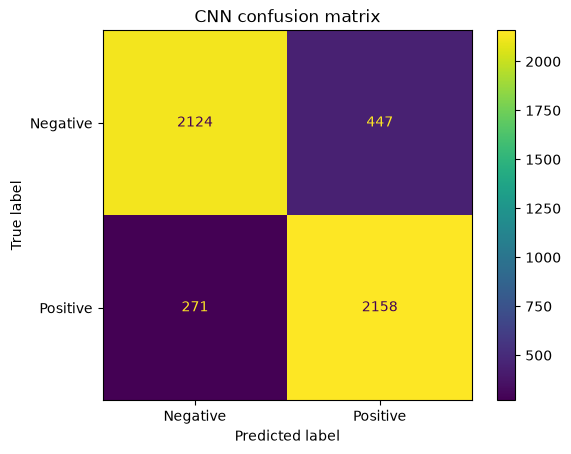

In [66]:
cm = confusion_matrix(test_labels, cnn_pred)

ConfusionMatrixDisplay(
    cm, display_labels=["Negative", "Positive"]
).plot(values_format="d")

plt.title("CNN confusion matrix")
plt.show()

### Q10.1

Does the model make substantially more errors for one class? not quite, even though false positive is almost doublethe false negative but when proportinating to total test amount it is not significantly more

What can a confusion matrix tell you—and what can it **not** tell you about the language causing those errors? from binary classification, it doesn't represent what or where the cause of the wrong predictions are from. like the linguistic quality that make the inaccurate prediction

---
# 11. Error analysis — diagnose the text

Complete confidence:
- predicted positive → `p_positive`
- predicted negative → `1 - p_positive`

In [75]:
error_df = pd.DataFrame({
    "text": test_texts,
    "true": test_labels,
    "pred": cnn_pred,
    "p_positive": cnn_prob
})

error_df["confidence"] = np.where(
    error_df["pred"] == 1,
    error_df["p_positive"],
    1 - error_df["p_positive"]
)


errors = error_df[error_df["true"] != error_df["pred"]].copy()
errors = errors.sort_values("confidence", ascending=False)

display(errors[["true", "pred", "confidence", "text"]].head(12))

# I take the lazy way, not by confidence,the 8 shortest review
errors["words"] = errors["text"].str.split().apply(len)
display(errors.head())


for (idx,row) in errors.iloc[:8].iterrows():
    print(f"true : {row.true} - conf : {row.confidence}")
    print(f"\t{row.text}")
    print("-"*50)

,true,pred,confidence,text
3103,0,1,0.996927,if daphne du <UNK> had set rebecca in 1950s sa...
4795,0,1,0.996492,the brave one is about a new york radio show h...
2397,0,1,0.995880,this is definitely one of the best kung fu mov...
2543,1,0,0.994327,the 80's is largely considered the decade in w...
3393,1,0,0.991050,the problem with so many people watching this ...
3500,0,1,0.990909,franco <UNK> the <UNK> of the <UNK> romeo and ...
2083,1,0,0.990907,10 respected directors each shot a short film ...
3955,0,1,0.990835,carole lombard and james stewart <UNK> try to ...
3303,1,0,0.988391,i missed the full four hour version when it wa...
3605,1,0,0.986964,now this is classic a friend of mine told me a...


,text,true,pred,p_positive,confidence,words
3103,if daphne du <UNK> had set rebecca in 1950s sa...,0,1,0.996927,0.996927,145
4795,the brave one is about a new york radio show h...,0,1,0.996492,0.996492,763
2397,this is definitely one of the best kung fu mov...,0,1,0.995880,0.995880,60
2543,the 80's is largely considered the decade in w...,1,0,0.005673,0.994327,463
3393,the problem with so many people watching this ...,1,0,0.008950,0.991050,341


true : 0 - conf : 0.604369580745697
	read the book forget the movie
--------------------------------------------------
true : 0 - conf : 0.8160614371299744
	more suspenseful more subtle much much more disturbing
--------------------------------------------------
true : 0 - conf : 0.6108583211898804
	i hope this group of film makers never re <UNK>
--------------------------------------------------
true : 0 - conf : 0.8624627590179443
	my first thoughts on this film were of using science fiction as a bad way to show naked women not a brilliant story line it had quite a good ending
--------------------------------------------------
true : 1 - conf : 0.9575419425964355
	what about dj cash money this film fails in part by not covering the mid to late 80s there was only a small mention of dj cheese in <UNK> br br also it's not
--------------------------------------------------
true : 1 - conf : 0.5408287048339844
	i have seen chasing the dragon several times and have enjoyed it each time the

## Activity — Diagnose at least 8 errors

Possible starting categories:
- negation
- contrast
- mixed sentiment
- long-range context
- rare / unknown vocabulary
- sarcasm / irony
- ambiguous label
- preprocessing / representation issue
- other

| Short excerpt | True | Predicted | Your diagnosis | Evidence from text |
|---|---|---|---|---|
| | | | | |
| | | | | |
| | | | | |
| | | | | |

### Q11.1
What is the most common pattern your group observed?

### Q11.2
Connect one error explicitly to a representation/model limitation.

### Q11.3
Would more epochs necessarily fix it?

### Q11.4
Find one error containing `<UNK>`. Can you conclude `<UNK>` caused the error? What additional evidence would you need?

---
# 12. Break the classifier

Make a small, meaningful change while trying to preserve intended sentiment. Predict what will happen **before** running it.

In [ ]:
def predict_sentiment(text, model=cnn_model):
    p = float(model.predict(
        np.array([text], dtype=object), verbose=0
    )[0][0])

    # TODO
    label = ______________________________

    return {"label": label, "p_positive": round(p, 4)}

In [ ]:
original = "The movie was entertaining and surprisingly funny."

# TODO: your modification
modified = "____________________________________________"

print("ORIGINAL:", original)
print(predict_sentiment(original))

print("\nMODIFIED:", modified)
print(predict_sentiment(modified))

### Q12.1

1. What did you change?
2. What did you predict would happen?
3. What actually happened?
4. What hypothesis does this suggest?
5. What additional experiment could test that hypothesis?

---
# 13. Optional controlled experiment

Change **one** variable only:
- sequence length;
- embedding dimension;
- CNN kernel size;
- vocabulary size;
- number of CNN filters.

Record your prediction **before** training.

**Variable:**  
**Original:**  
**New:**  
**Prediction:**  
**Observed:**  
**Interpretation:**

---
# 14. Exit ticket

1. Difference between a token ID and an embedding?
2. What does CountVectorizer capture that TF–IDF changes?
3. What limitation is shared by Bag-of-Words and unigram TF–IDF?
4. Why can average pooling lose useful information?
5. What does CNN add?
6. Why is error analysis necessary even with high test accuracy?

## Workflow

`inspect text → represent → model → evaluate → inspect errors → diagnose → hypothesize → experiment`